# Data Challenge II — Intelligence en Données de Santé
**Date :** 2 février 2026  
**Étudiant :** EL BACHA Mohammed - KENNICHE Redouane - LAMLOUH Awataf (Groupe 2)  
**Projet :** Modélisation prédictive des exacerbations de l'asthme et génération de données synthétiques

---

## Objectif du Rapport
Ce projet s'inscrit dans le cadre du **Data Challenge II (DC2)**. L'enjeu est de mobiliser des outils de Machine Learning pour analyser des données réelles de patients asthmatiques.

Ce projet s'articule autour de deux objectifs majeurs :

- Prédiction de la survenue d'exacerbations (Classification) : Développer un modèle (notamment via un classifieur Naive Bayes) pour identifier le risque binaire (0 ou 1) qu'un patient subisse au moins une crise dans l'année suivant le début de son traitement.

- Conception d'un Pipeline Machine Learning automatisé : Construire un flux de traitement robuste capable d'ingérer de nouvelles données brutes (de structure strictement identique au fichier d'entraînement) pour générer ces prédictions à la chaîne et de manière reproductible.

---

## Organisation du Notebook
1.  **Exploration & Nettoyage** : Analyse descriptive et recodage de la variable cible.
2.  **Ingénierie des caractéristiques** : Transformation des variables de coûts et gestion des variables catégorielles.
3.  **Modélisation (Partie I)** : Construction d'un pipeline Scikit-learn avec un modèle Naive Bayes.
4.  **Évaluation** : Analyse des performances (Score F1, Précision) et validation sur le set de test.
5.  **Export des résultats** : Génération du fichier `prediction.csv` (colonnes : `patid`, `prediction`).

---

## 1. Partie I : Prédiction de la survenue d'exacerbations

L'objectif clinique est d'identifier, dès le début du suivi, les patients les plus à risque de subir une exacerbation. Ces événements sont souvent synonymes d'une dégradation de la qualité de vie et d'un coût de santé important.

### 1.1 Chargement des données et définition de la cible
Nous utilisons le fichier `trainDataDC2.csv.gz`. La variable d'intérêt `post_index_exacerbations365` (nombre d'exacerbations) est transformée en variable binaire :
* **0** : Pas d'exacerbation constatée.
* **1** : Survenue d'au moins une exacerbation ($> 0$).



### 1.2 Description des variables pré-index
Les variables utilisées pour la prédiction reflètent l'état de santé du patient durant l'année précédant la date index :

| Catégorie | Variables clés |
| :--- | :--- |
| **Comorbidités** | Bronchite, Laryngite, GERD (RGO), Pneumonie, Rhinite, Sinusite. |
| **Démographie** | Âge au début du traitement (`index_age`), Sexe (`female`). |
| **Utilisation des soins** | Utilisation de SABA (`total_pre_index_cannisters_365`), frais pharmaceutiques. |
| **Transformées** | Logarithmes des charges financières pour stabiliser la variance. |

---

## 2. Prétraitement et Pipeline Scikit-learn

Pour garantir la reproductibilité et éviter la fuite de données (*data leakage*), nous utilisons l'objet `Pipeline` de Scikit-learn. Cela permet d'enchaîner le centrage-réduction (`StandardScaler`), l'encodage et l'entraînement du modèle `GaussianNB`.

In [ ]:
# --- 1. Système et Outils de base ---
import time
import warnings
warnings.filterwarnings('ignore')

# --- 2. Manipulation de données et calcul numérique ---
import polars as pl
import numpy as np

# --- 3. Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- 4. Scikit-learn : Prétraitement et Pipelines ---
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SkPipeline # Utilisé de préférence avec l'alias

# --- 5. Imbalanced-learn : Gestion du déséquilibre ---
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# --- 6. Scikit-learn & XGBoost : Modèles (Algorithmes) ---
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier, HistGradientBoostingClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
import xgboost as xgb

# --- 7. Scikit-learn : Évaluation des performances ---
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve
)

In [ ]:
#Chargement des donneés
data_path= "trainDataDC2.csv.gz"
df = pl.read_csv(data_path)

In [ ]:
print(f"Dimensions du jeu de données : {df.shape}")

Dimensions du jeu de données : (14575, 21)


In [ ]:
df.describe()

statistic,patid,index_age,previous_asthma_drugs,total_pre_index_cannisters_365,post_index_exacerbations365,pneumonia,sinusitis,acute_bronchitis,acute_laryngitis,upper_respiratory_infection,gerd,rhinitis,adherence,total_pre_index_charge,pre_asthma_days,pre_asthma_charge,pre_asthma_pharma_charge,drug_s,female,log_charges,log_asthma_charge
str,f64,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str
"""count""",14575.0,"""14575""","""14575""","""14575""",14575.0,"""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575""","""14575"""
"""null_count""",0.0,"""0""","""0""","""0""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0"""
"""mean""",1.3170e9,null,null,null,0.175163,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""std""",1.5464e8,null,null,null,0.638298,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""min""",1.0738e9,"""12""","""1""","""0""",0.0,"""0""","""0""","""0""","""0""","""0""","""0""","""0""","""0.0054495913""","""1""","""0""","""0""","""1""","""0""","""0""","""0""","""0"""
"""25%""",1.1835e9,null,null,null,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""50%""",1.2824e9,null,null,null,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""75%""",1.4937e9,null,null,null,0.0,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null
"""max""",1.7719e9,"""NA""","""NA""","""NA""",13.0,"""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA""","""NA"""


In [ ]:
#Vérification des patients uniques
print(f"\nVérification des doublons patid :")
duplicate_subjects = (df['patid'].value_counts() > 1).sum()
print(f"Nombre de patid en double: {duplicate_subjects}")


Vérification des doublons patid :
Nombre de patid en double: shape: (1, 2)
┌───────┬───────┐
│ patid ┆ count │
│ ---   ┆ ---   │
│ u32   ┆ u32   │
╞═══════╪═══════╡
│ 14575 ┆ 0     │
└───────┴───────┘


## 3. Partitionner les données

En Machine Learning, la règle d'or est simple : nous ne devons jamais évaluer notre modèle sur les données qu'il a utilisées pour apprendre. Sinon, il se contente d'apprendre les patients par cœur (surapprentissage ou overfitting), et sera incapable de faire des prédictions fiables sur de nouveaux patients.

Pour évaluer ses véritables capacités, nous allons donc couper notre jeu de données en deux :
A. Séparer l'objectif (y) des indices (X)

Avant de couper, nous séparons les rôles des colonnes :

  - La cible (y) : C'est ce que nous voulons prédire (la variable post_index_exacerbations365).

  - Les variables prédictives (X) : Ce sont tous nos indices médicaux (âge, traitements, coûts...). Nous en profitons pour retirer l'identifiant patient (patid) qui n'a évidemment aucun pouvoir prédictif.Nous écartons également les variables commençant par log_, car ce sont des données mathématiques redondantes qui fausseraient notre modèle.

B. Diviser en "Entraînement" et "Test"

Nous utilisons la fonction train_test_split de scikit-learn pour créer nos deux groupes :

  1- Le jeu d'entraînement (Train, 80% des données) : Le modèle va l'analyser pour comprendre ce qui déclenche une exacerbation.

  2- Le jeu de test (Test, 20% des données) :Nous cachons ces patients au modèle pendant son apprentissage pour vérifier, à la fin, s'il sait deviner leur état de santé.

In [ ]:
df.columns

['patid',
 'index_age',
 'previous_asthma_drugs',
 'total_pre_index_cannisters_365',
 'post_index_exacerbations365',
 'pneumonia',
 'sinusitis',
 'acute_bronchitis',
 'acute_laryngitis',
 'upper_respiratory_infection',
 'gerd',
 'rhinitis',
 'adherence',
 'total_pre_index_charge',
 'pre_asthma_days',
 'pre_asthma_charge',
 'pre_asthma_pharma_charge',
 'drug_s',
 'female',
 'log_charges',
 'log_asthma_charge']

In [ ]:
# 1. On isole la variable à prédire (la cible / target)
target = df.select(['post_index_exacerbations365'])
target.head(n=3)

post_index_exacerbations365
i64
0
2
0


In [ ]:
# 2. On sélectionne explicitement toutes les variables qui vont nous servir d'indices (les features)
# On omet'patid' et les variables 'log_...'
features = df.select([
    'index_age',
    'previous_asthma_drugs',
    'total_pre_index_cannisters_365',
    'pneumonia',
    'sinusitis',
    'acute_bronchitis',
    'acute_laryngitis',
    'upper_respiratory_infection',
    'gerd',
    'rhinitis',
    'adherence',
    'total_pre_index_charge',
    'pre_asthma_days',
    'pre_asthma_charge',
    'pre_asthma_pharma_charge',
    'drug_s',
    'female',
])

In [ ]:
# Division Train / Test
X_train, X_test, y_train, y_test = skl.model_selection.train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=42,
)

## 4. Préparer les données :

Avant de donner nos données au modèle, nous devons les préparer pour qu'il puisse les comprendre correctement et cela en trois étapes clés :

  - L'imputation : Les données médicales sont souvent incomplètes. Nous allons combler ces valeurs manquantes par des indicateurs statistiques robustes.Les cases vides (NA) font planter les modèles. Au lieu de supprimer les dossiers patients incomplets, nous "imputons" une valeur logique : la médiane pour les variables numériques, et la catégorie la plus fréquente pour les variables textuelles.

  - La standardisation (Mise à l'échelle) : Nous ajustons les variables numériques continues. Sans cela, une variable avec de grandes valeurs (comme les coûts médicaux) biaiserait l'algorithme en écrasant le poids d'une variable plus petite (comme l'âge).

  - L'encodage (One-Hot) : Nous traduisons les variables catégorielles (qualitatives) en un format binaire (0 ou 1) que la machine peut mathématiquement interpréter.

In [ ]:
# FONCTION DE BINARISATION
def binarize_outcome(data):
    if isinstance(data, pl.Series):
        return (data > 0).cast(pl.Int64)
    else:
        df_bin = data.with_columns(
            pl.when(pl.col('post_index_exacerbations365') > 0)
            .then(1).otherwise(0).alias('survenue')
        )
        return df_bin['survenue']

# On applique
y_train = binarize_outcome(y_train)
y_test = binarize_outcome(y_test)
print("Binarisation réussie !")

# GROUPES DE VARIABLES
categorical_features = [
    'previous_asthma_drugs', 'pneumonia', 'sinusitis', 'acute_bronchitis',
    'acute_laryngitis', 'upper_respiratory_infection', 'gerd', 'rhinitis',
    'drug_s', 'female'
]
numeric_features_int = [
    'index_age', 'total_pre_index_cannisters_365', 'pre_asthma_days', 'pre_asthma_charge'
]
numeric_features_float = [
    'adherence', 'total_pre_index_charge', 'pre_asthma_pharma_charge'
]

# TRANSFORMATEURS ET PIPELINES
def cast_numeric_int(s): return s.cast(pl.Int64, strict=False)
def cast_numeric_float(s): return s.cast(pl.Float64, strict=False)

cast_int_transformer = FunctionTransformer(cast_numeric_int)
cast_float_transformer = FunctionTransformer(cast_numeric_float)

float_transformer = Pipeline(steps=[
    ('caster', cast_float_transformer),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

int_transformer = Pipeline(steps=[
    ('caster', cast_int_transformer),
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False)), # sparse_output=False pour Naive Bayes
])

# ASSEMBLAGE FINAL
preprocessor = ColumnTransformer(transformers=[
    ('num_float', float_transformer, numeric_features_float),
    ('num_int', int_transformer, numeric_features_int),
    ('cat', categorical_transformer, categorical_features),
])

print("Pipeline de prétraitement (preprocessor) créé avec succès !")

Binarisation réussie !
Pipeline de prétraitement (preprocessor) créé avec succès !


## 5. Naive Bayes — Étude Comparative des 3 Approches

Nous évaluons ici trois stratégies pour gérer le déséquilibre des classes :

1. **Sans SMOTE** : Naive Bayes brut (seuil 0.5)
2. **Avec SMOTE** : Rééchantillonnage synthétique de la classe minoritaire
3. **Méthode optimisée** : Ajustement des probabilités a priori (priors), stabilisation par apprentissage ensembliste (Bagging) et calibrage dynamique du seuil de décision sur un ensemble de validation.

In [ ]:
#  FONCTION UTILITAIRE : optimisation du seuil
def trouver_seuil_optimal(model, X_val, y_val):
    """Cherche le seuil de décision qui maximise le F1-Score sur la validation."""
    y_proba = model.predict_proba(X_val)[:, 1]
    best_seuil, best_f1 = 0.5, 0.0
    for s in np.arange(0.10, 0.90, 0.05):
        y_tmp = (y_proba >= s).astype(int)
        f1 = f1_score(y_val, y_tmp, zero_division=0)
        if f1 > best_f1:
            best_f1, best_seuil = f1, s
    return best_seuil, best_f1


### 5.1 — Naive Bayes sans SMOTE (Baseline)

  NAIVE BAYES — Version 1 : SANS SMOTE (Baseline)
Cross-validation F1 : 0.087 (+/- 0.013)

 Rapport de Classification :
              precision    recall  f1-score   support

    Sain (0)       0.88      0.95      0.91      2551
   Crise (1)       0.13      0.05      0.07       364

    accuracy                           0.84      2915
   macro avg       0.50      0.50      0.49      2915
weighted avg       0.78      0.84      0.81      2915

ROC-AUC : 0.538


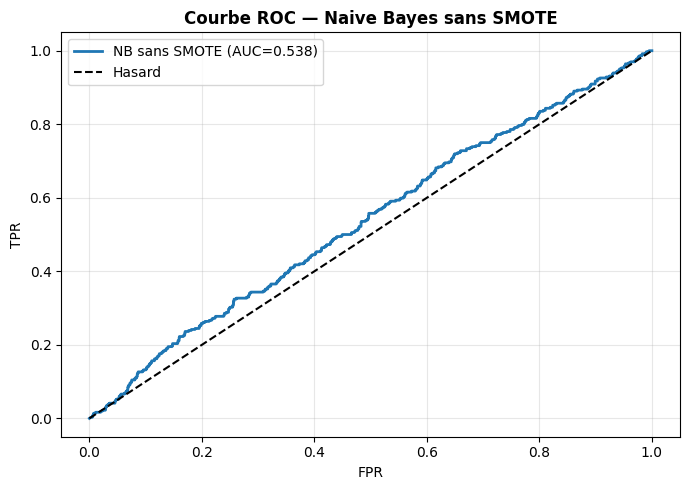

In [ ]:
print('='*60)
print('  NAIVE BAYES — Version 1 : SANS SMOTE (Baseline)')
print('='*60)

nb_pipeline = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

from sklearn.model_selection import cross_val_score
cv_scores_nb = cross_val_score(nb_pipeline, X_train, y_train, cv=5, scoring='f1')
print(f'Cross-validation F1 : {cv_scores_nb.mean():.3f} (+/- {cv_scores_nb.std():.3f})')

nb_pipeline.fit(X_train, y_train)
y_pred_nb_base  = nb_pipeline.predict(X_test)
y_proba_nb_base = nb_pipeline.predict_proba(X_test)[:, 1]

print('\n Rapport de Classification :')
print(classification_report(y_test, y_pred_nb_base, target_names=['Sain (0)', 'Crise (1)']))

fpr_b, tpr_b, _ = roc_curve(y_test, y_proba_nb_base)
auc_b = auc(fpr_b, tpr_b)
print(f'ROC-AUC : {auc_b:.3f}')

# Courbe ROC
plt.figure(figsize=(7, 5))
plt.plot(fpr_b, tpr_b, color='#1f77b4', lw=2, label=f'NB sans SMOTE (AUC={auc_b:.3f})')
plt.plot([0,1],[0,1],'k--', label='Hasard')
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('Courbe ROC — Naive Bayes sans SMOTE', fontweight='bold')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()


### 5.2 — Naive Bayes avec SMOTE

  NAIVE BAYES — Version 2 : AVEC SMOTE
Cross-validation F1 : 0.190 (+/- 0.008)

 Rapport de Classification :
              precision    recall  f1-score   support

    Sain (0)       0.88      0.53      0.66      2551
   Crise (1)       0.13      0.49      0.21       364

    accuracy                           0.53      2915
   macro avg       0.50      0.51      0.43      2915
weighted avg       0.79      0.53      0.61      2915

ROC-AUC : 0.530


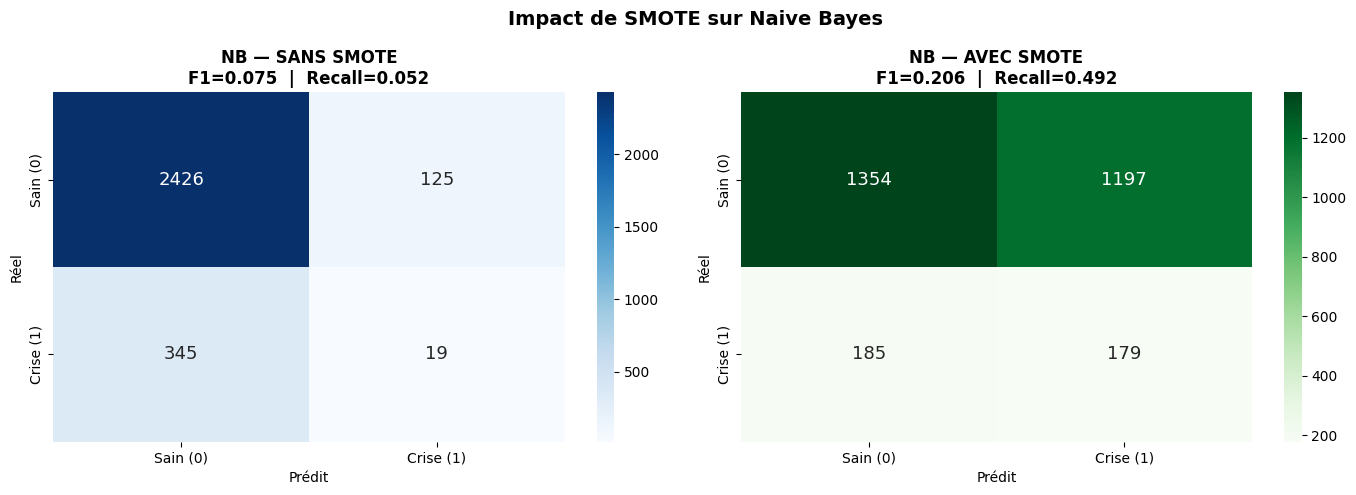


Impact SMOTE :
  Recall  : 0.052 → 0.492
  F1      : 0.075 → 0.206


In [ ]:
print('='*60)
print('  NAIVE BAYES — Version 2 : AVEC SMOTE')
print('='*60)

smote_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', GaussianNB())
])

cv_scores_smote = cross_val_score(smote_pipeline, X_train, y_train, cv=5, scoring='f1')
print(f'Cross-validation F1 : {cv_scores_smote.mean():.3f} (+/- {cv_scores_smote.std():.3f})')

smote_pipeline.fit(X_train, y_train)
y_pred_nb_smote  = smote_pipeline.predict(X_test)
y_proba_nb_smote = smote_pipeline.predict_proba(X_test)[:, 1]

print('\n Rapport de Classification :')
print(classification_report(y_test, y_pred_nb_smote, target_names=['Sain (0)', 'Crise (1)']))
print(f'ROC-AUC : {roc_auc_score(y_test, y_proba_nb_smote):.3f}')

# Matrices de confusion côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
noms = ['Sain (0)', 'Crise (1)']
for ax, y_p, titre, cmap in zip(
    axes,
    [y_pred_nb_base, y_pred_nb_smote],
    ['NB — SANS SMOTE', 'NB — AVEC SMOTE'],
    ['Blues', 'Greens']
):
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=noms, yticklabels=noms, annot_kws={'size':13})
    ax.set_title(f'{titre}\nF1={f1_score(y_test, y_p):.3f}  |  Recall={recall_score(y_test, y_p):.3f}',
                 fontweight='bold')
    ax.set_ylabel('Réel'); ax.set_xlabel('Prédit')
plt.suptitle('Impact de SMOTE sur Naive Bayes', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'\nImpact SMOTE :')
print(f'  Recall  : {recall_score(y_test, y_pred_nb_base):.3f} → {recall_score(y_test, y_pred_nb_smote):.3f}')
print(f'  F1      : {f1_score(y_test, y_pred_nb_base):.3f} → {f1_score(y_test, y_pred_nb_smote):.3f}')


### 5.3 — Naive Bayes — Méthode Améliorée

**Split 60/20/20 stratifié + Priors balancés + Bagging + Seuil optimal**


In [ ]:
print('='*60)
print('  NAIVE BAYES — Version 3 : METHODE AMELIOREE')
print('='*60)

# Split 60/20/20 stratifié :
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)
print(f'Train : {len(X_tr)} | Val : {len(X_val)} | Test : {len(X_test)}')
print(f'% crises — Train: {y_tr.mean():.1%}  Val: {y_val.mean():.1%}  Test: {y_test.mean():.1%}')

#  Priors balancés + Bagging :
base_nb = GaussianNB(priors=[0.5, 0.5])
bagging_nb = BaggingClassifier(estimator=base_nb, random_state=42, n_jobs=-1)

nb_best_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', bagging_nb)
])

param_nb = {
    'classifier__n_estimators': [50, 100, 150, 200],
    'classifier__max_samples':  [0.5, 0.7, 0.9, 1.0],
    'classifier__max_features': [0.5, 0.7, 1.0],
    'classifier__estimator__var_smoothing': [1e-9, 1e-7, 1e-5, 1e-3],
    'classifier__estimator__priors': [[0.5,0.5], [0.3,0.7], None]
}

debut = time.time()
search_nb = RandomizedSearchCV(nb_best_pipe, param_nb, n_iter=20,
                               scoring='f1', cv=3, random_state=42,
                               n_jobs=-1, verbose=0)
search_nb.fit(X_tr, y_tr)
best_nb_model = search_nb.best_estimator_

#  Seuil optimal sur la validation :
seuil_nb_opt, f1_val_nb = trouver_seuil_optimal(best_nb_model, X_val, y_val)
print(f'Seuil optimal : {seuil_nb_opt:.2f}  (F1 val = {f1_val_nb:.3f})')

#  Évaluation finale sur le Test :
y_proba_nb_opt = best_nb_model.predict_proba(X_test)[:, 1]
y_pred_nb_opt  = (y_proba_nb_opt >= seuil_nb_opt).astype(int)

print(f'Meilleurs params : {search_nb.best_params_}')
print('\n--- Rapport de Classification ---')
print(classification_report(y_test, y_pred_nb_opt, target_names=['Sain (0)', 'Crise (1)']))
print(f'ROC-AUC : {roc_auc_score(y_test, y_proba_nb_opt):.3f}')


  NAIVE BAYES — Version 3 : METHODE AMELIOREE
Train : 8745 | Val : 2915 | Test : 2915
% crises — Train: 11.1%  Val: 11.1%  Test: 12.5%
Seuil optimal : 0.60  (F1 val = 0.210)
Meilleurs params : {'classifier__n_estimators': 100, 'classifier__max_samples': 0.9, 'classifier__max_features': 0.7, 'classifier__estimator__var_smoothing': 1e-07, 'classifier__estimator__priors': [0.3, 0.7]}

--- Rapport de Classification ---
              precision    recall  f1-score   support

    Sain (0)       0.89      0.42      0.57      2551
   Crise (1)       0.14      0.65      0.23       364

    accuracy                           0.45      2915
   macro avg       0.52      0.54      0.40      2915
weighted avg       0.80      0.45      0.53      2915

ROC-AUC : 0.548


### 5.4 — Comparaison des 3 Versions Naive Bayes

  COMPARAISON — 3 VERSIONS DE NAIVE BAYES
                    Version  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   NB sans SMOTE (baseline)     0.839      0.132   0.052     0.075    0.538
              NB avec SMOTE     0.526      0.130   0.492     0.206    0.530
NB Amélioré (Bagging+Seuil)     0.447      0.138   0.654     0.228    0.548


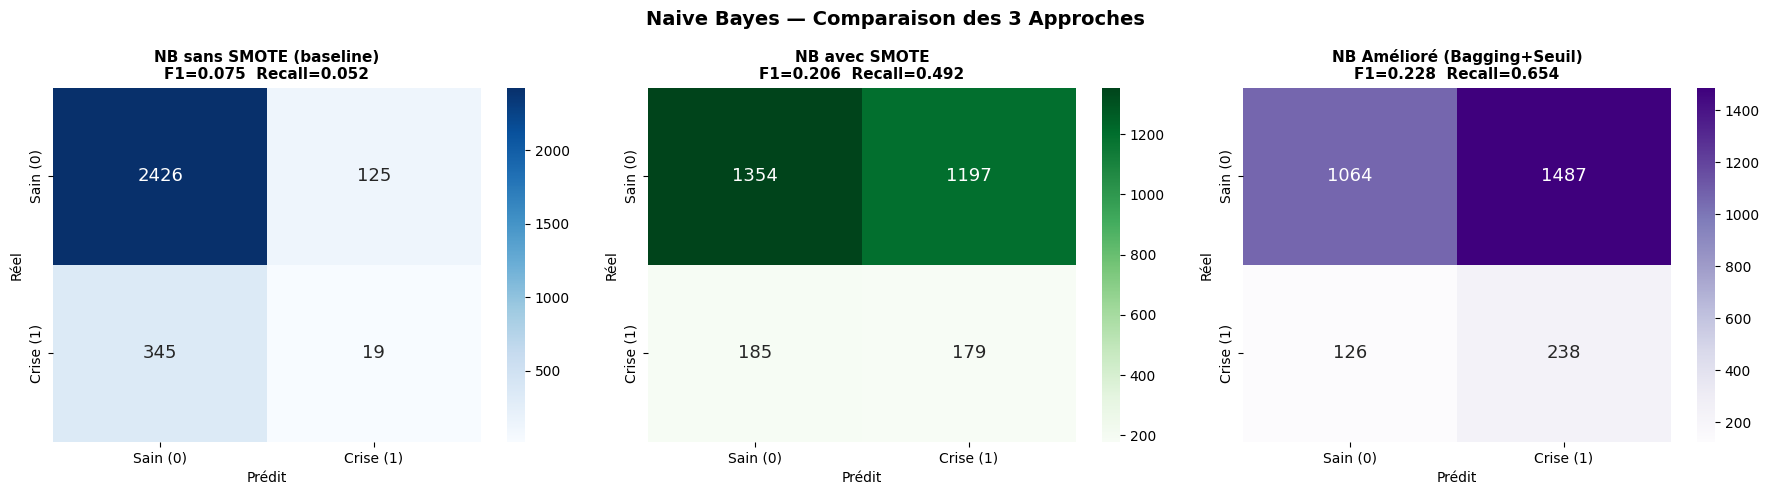

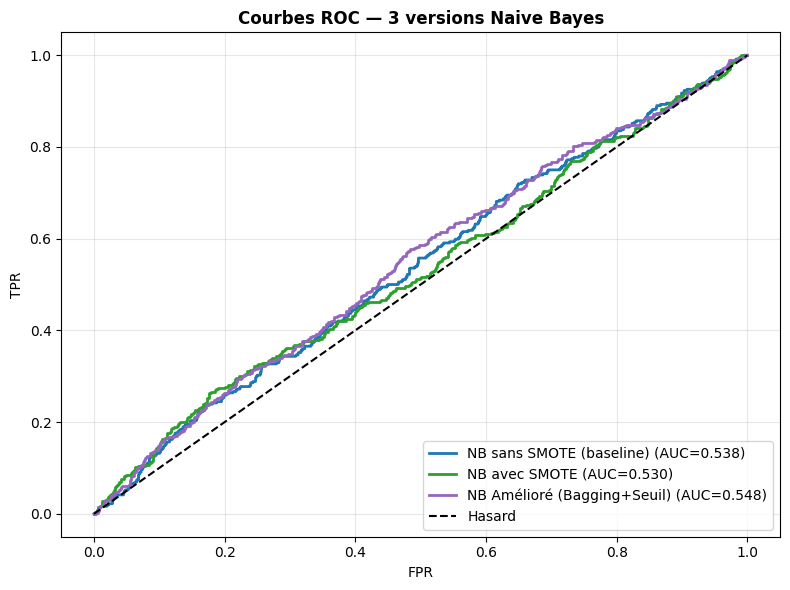


=> La version améliorée est retenue pour la comparaison finale.


In [ ]:
print('='*70)
print('  COMPARAISON — 3 VERSIONS DE NAIVE BAYES')
print('='*70)

versions_nb = {
    'NB sans SMOTE (baseline)':      (y_pred_nb_base,  y_proba_nb_base),
    'NB avec SMOTE':                  (y_pred_nb_smote, y_proba_nb_smote),
    'NB Amélioré (Bagging+Seuil)':    (y_pred_nb_opt,   y_proba_nb_opt),
}

rows_nb = []
for name, (y_p, y_pr) in versions_nb.items():
    rows_nb.append({
        'Version':    name,
        'Accuracy':   accuracy_score(y_test, y_p),
        'Precision':  precision_score(y_test, y_p, zero_division=0),
        'Recall':     recall_score(y_test, y_p, zero_division=0),
        'F1-Score':   f1_score(y_test, y_p, zero_division=0),
        'ROC-AUC':    roc_auc_score(y_test, y_pr),
    })

nb_compare_df = pd.DataFrame(rows_nb)
print(nb_compare_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

#  Graphique comparatif :
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
noms_classes = ['Sain (0)', 'Crise (1)']
cmaps3 = ['Blues', 'Greens', 'Purples']

for ax, (name, (y_p, _)), cmap in zip(axes, versions_nb.items(), cmaps3):
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=ax,
                xticklabels=noms_classes, yticklabels=noms_classes,
                annot_kws={'size': 13})
    ax.set_title(f'{name}\nF1={f1_score(y_test,y_p):.3f}  Recall={recall_score(y_test,y_p):.3f}',
                 fontweight='bold', fontsize=11)
    ax.set_ylabel('Réel'); ax.set_xlabel('Prédit')

plt.suptitle('Naive Bayes — Comparaison des 3 Approches', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

#  Courbes ROC des 3 versions :
plt.figure(figsize=(8, 6))
colors_nb = ['#1f77b4', '#2ca02c', '#9467bd']
for (name, (y_p, y_pr)), col in zip(versions_nb.items(), colors_nb):
    fpr_n, tpr_n, _ = roc_curve(y_test, y_pr)
    plt.plot(fpr_n, tpr_n, lw=2, color=col,
             label=f'{name} (AUC={auc(fpr_n,tpr_n):.3f})')
plt.plot([0,1],[0,1],'k--', label='Hasard')
plt.xlabel('FPR'); plt.ylabel('TPR')
plt.title('Courbes ROC — 3 versions Naive Bayes', fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

print('\n=> La version améliorée est retenue pour la comparaison finale.')
# On garde y_pred_nb_opt et y_proba_nb_opt pour la suite
y_pred_nb   = y_pred_nb_opt
y_proba_nb  = y_proba_nb_opt


Cette analyse comparative illustre l'évolution de nos stratégies de modélisation pour surmonter le déséquilibre des données cliniques dans la prédiction des exacerbations d'asthme:

- Le modèle de base (sans SMOTE) est cliniquement aveugle aux patients malades (Recall de 5%), masquant son échec derrière une exactitude artificielle de 84%.

- Le rééquilibrage par SMOTE (Version 2) corrige ce biais en détectant 49% des crises, au prix d'une augmentation logique des fausses alertes.

- La Version 3 (Méthode améliorée) est de loin le meilleur modèle : elle offre le meilleur F1-Score (0.23) et sécurise la détection en identifiant 65% des exacerbations (Recall).

En définitive, cette progression démontre que le recours à une méthode optimisée et rééquilibrée est indispensable pour obtenir un outil prédictif qui soit à la fois robuste statistiquement et sécurisant pour une application médicale réelle.

## 6. Extension de l'Étude : Autres Modèles Avancés

Conformément a la consigne, notre démarche s'est d'abord concentrée sur l'implémentation et l'optimisation du classifieur **Naive Bayes**. Ce modèle nous a servi de *baseline* (modèle de référence) et a permis de mettre en évidence les défis inhérents à notre étude (fort déséquilibre des classes).

Cependant, s'arrêter à un seul algorithme limite la portée clinique de l'outil. Nous avons donc fait le choix d'étendre notre script en testant d'autres algorithmes pour les raisons suivantes :

* **Les limites de l'hypothèse de "naïveté" :** Le Naive Bayes suppose que toutes les variables sont indépendantes les unes des autres. Or, en médecine clinique (et particulièrement pour l'asthme), les variables sont profondément corrélées (l'âge, le nombre de traitements précédents, les comorbidités comme la pneumonie, etc.).
* **Le plafond de performance :** Même après le rééquilibrage par SMOTE, le Naive Bayes atteint rapidement ses limites mathématiques sur nos données (F1-Score plafonné).
* **La recherche d'interactions complexes :** Pour espérer déployer un outil prédictif fiable en milieu hospitalier, il est indispensable de le confronter à des modèles capables de capter des relations non linéaires complexes, tels que les modèles ensemblistes (**Random Forest**, **Gradient Boosting**, **XGBoost**).


Pour tous les modèles suivants, on applique la même stratégie :
- `class_weight='balanced'` (ou équivalent) au lieu de SMOTE
- `RandomizedSearchCV` (plus rapide que GridSearchCV)
- Seuil de décision optimisé sur le jeu de validation
- Même split 60/20/20 stratifié (X_tr / X_val / X_test)

### 6.1 — Régression Logistique

In [ ]:
print('='*60)
print('  1 - REGRESSION LOGISTIQUE')
print('='*60)
debut = time.time()

lr_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=42
    ))
])
param_lr = {
    'classifier__C':      [0.001, 0.01, 0.1, 1, 10, 100],
    'classifier__solver': ['lbfgs', 'liblinear']
}
search_lr = RandomizedSearchCV(lr_pipe, param_lr, n_iter=12,
                               scoring='f1', cv=3, random_state=42,
                               n_jobs=-1, verbose=0)
search_lr.fit(X_tr, y_tr)
best_lr = search_lr.best_estimator_
seuil_lr, _ = trouver_seuil_optimal(best_lr, X_val, y_val)
y_proba_lr = best_lr.predict_proba(X_test)[:, 1]
y_pred_lr  = (y_proba_lr >= seuil_lr).astype(int)
print(f'Seuil={seuil_lr:.2f} | ')
print(f'  F1={f1_score(y_test,y_pred_lr):.3f} | AUC={roc_auc_score(y_test,y_proba_lr):.3f}')
print(classification_report(y_test, y_pred_lr, target_names=['Sain (0)', 'Crise (1)']))


  1 - REGRESSION LOGISTIQUE
Seuil=0.50 | 
  F1=0.238 | AUC=0.569
              precision    recall  f1-score   support

    Sain (0)       0.90      0.57      0.70      2551
   Crise (1)       0.15      0.54      0.24       364

    accuracy                           0.57      2915
   macro avg       0.53      0.56      0.47      2915
weighted avg       0.80      0.57      0.64      2915



### 6.2 — Arbre de Décision

In [ ]:
print('='*60)
print('  2 - ARBRE DE DECISION')
print('='*60)
debut = time.time()

base_dt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
bagging_dt = BaggingClassifier(estimator=base_dt, random_state=42, n_jobs=-1)
dt_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', bagging_dt)
])
param_dt = {
    'classifier__estimator__max_depth':        [3, 5, 7, 10, None],
    'classifier__estimator__min_samples_leaf': [1, 5, 10, 20],
    'classifier__estimator__criterion':        ['gini', 'entropy'],
    'classifier__n_estimators':                [50, 100, 150],
    'classifier__max_samples':                 [0.5, 0.7, 0.9],
    'classifier__max_features':                [0.5, 0.7, 1.0]
}
search_dt = RandomizedSearchCV(dt_pipe, param_dt, n_iter=20,
                               scoring='f1', cv=3, random_state=42,
                               n_jobs=-1, verbose=0)
search_dt.fit(X_tr, y_tr)
best_dt = search_dt.best_estimator_
seuil_dt, _ = trouver_seuil_optimal(best_dt, X_val, y_val)
y_proba_dt = best_dt.predict_proba(X_test)[:, 1]
y_pred_dt  = (y_proba_dt >= seuil_dt).astype(int)
print(f'Seuil={seuil_dt:.2f}')
print(f'  F1={f1_score(y_test,y_pred_dt):.3f} | AUC={roc_auc_score(y_test,y_proba_dt):.3f}')
print(classification_report(y_test, y_pred_dt, target_names=['Sain (0)', 'Crise (1)']))


  2 - ARBRE DE DECISION
Seuil=0.50
  F1=0.235 | AUC=0.571
              precision    recall  f1-score   support

    Sain (0)       0.89      0.62      0.73      2551
   Crise (1)       0.15      0.49      0.23       364

    accuracy                           0.60      2915
   macro avg       0.52      0.55      0.48      2915
weighted avg       0.80      0.60      0.67      2915



### 6.3 — Random Forest

In [ ]:
print('='*60)
print('  3 - RANDOM FOREST')
print('='*60)
debut = time.time()

rf_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        class_weight='balanced', random_state=42
    ))
])
param_rf = {
    'classifier__n_estimators':     [100, 200, 300],
    'classifier__max_depth':        [5, 10, 15, None],
    'classifier__min_samples_leaf': [1, 5, 10],
    'classifier__max_features':     ['sqrt', 'log2', 0.5]
}
search_rf = RandomizedSearchCV(rf_pipe, param_rf, n_iter=20,
                               scoring='f1', cv=3, random_state=42,
                               n_jobs=-1, verbose=0)
search_rf.fit(X_tr, y_tr)
best_rf = search_rf.best_estimator_
seuil_rf, _ = trouver_seuil_optimal(best_rf, X_val, y_val)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]
y_pred_rf  = (y_proba_rf >= seuil_rf).astype(int)
print(f'Seuil={seuil_rf:.2f}')
print(f'  F1={f1_score(y_test,y_pred_rf):.3f} | AUC={roc_auc_score(y_test,y_proba_rf):.3f}')
print(classification_report(y_test, y_pred_rf, target_names=['Sain (0)', 'Crise (1)']))


  3 - RANDOM FOREST
Seuil=0.45
  F1=0.228 | AUC=0.568
              precision    recall  f1-score   support

    Sain (0)       0.90      0.31      0.46      2551
   Crise (1)       0.13      0.75      0.23       364

    accuracy                           0.37      2915
   macro avg       0.52      0.53      0.34      2915
weighted avg       0.80      0.37      0.43      2915



### 6.4 — K-Nearest Neighbors (KNN)

In [ ]:
print('='*60)
print('  4 - KNN')
print('='*60)
debut = time.time()

base_knn   = KNeighborsClassifier()
bagging_knn = BaggingClassifier(estimator=base_knn, random_state=42, n_jobs=-1)
knn_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', bagging_knn)
])
param_knn = {
    'classifier__estimator__n_neighbors': [3, 5, 7, 11, 15],
    'classifier__estimator__weights':     ['uniform', 'distance'],
    'classifier__estimator__metric':      ['euclidean', 'manhattan'],
    'classifier__n_estimators':           [30, 50, 100],
    'classifier__max_samples':            [0.5, 0.7, 0.9]
}
search_knn = RandomizedSearchCV(knn_pipe, param_knn, n_iter=15,
                                scoring='f1', cv=3, random_state=42,
                                n_jobs=-1, verbose=0)
search_knn.fit(X_tr, y_tr)
best_knn = search_knn.best_estimator_
seuil_knn, _ = trouver_seuil_optimal(best_knn, X_val, y_val)
y_proba_knn = best_knn.predict_proba(X_test)[:, 1]
y_pred_knn  = (y_proba_knn >= seuil_knn).astype(int)
print(f'Seuil={seuil_knn:.2f}')
print(f'  F1={f1_score(y_test,y_pred_knn):.3f} | AUC={roc_auc_score(y_test,y_proba_knn):.3f}')
print(classification_report(y_test, y_pred_knn, target_names=['Sain (0)', 'Crise (1)']))


  4 - KNN
Seuil=0.10
  F1=0.178 | AUC=0.510
              precision    recall  f1-score   support

    Sain (0)       0.87      0.64      0.74      2551
   Crise (1)       0.12      0.34      0.18       364

    accuracy                           0.60      2915
   macro avg       0.50      0.49      0.46      2915
weighted avg       0.78      0.60      0.67      2915



### 6.5 — SVM

In [ ]:
print('='*60)
print('  5 - SVM')
print('='*60)
debut = time.time()

svm_cal  = CalibratedClassifierCV(
    LinearSVC(class_weight='balanced', dual=False, max_iter=3000, random_state=42),
    cv=3
)
svm_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', svm_cal)
])
param_svm = {'classifier__estimator__C': [0.001, 0.01, 0.1, 1, 10, 100]}
search_svm = RandomizedSearchCV(svm_pipe, param_svm, n_iter=6,
                                scoring='f1', cv=3, random_state=42,
                                n_jobs=-1, verbose=0)
search_svm.fit(X_tr, y_tr)
best_svm = search_svm.best_estimator_
seuil_svm, _ = trouver_seuil_optimal(best_svm, X_val, y_val)
y_proba_svm = best_svm.predict_proba(X_test)[:, 1]
y_pred_svm  = (y_proba_svm >= seuil_svm).astype(int)
print(f'Seuil={seuil_svm:.2f}')
print(f'  F1={f1_score(y_test,y_pred_svm):.3f} | AUC={roc_auc_score(y_test,y_proba_svm):.3f}')
print(classification_report(y_test, y_pred_svm, target_names=['Sain (0)', 'Crise (1)']))


  5 - SVM
Seuil=0.10
  F1=0.231 | AUC=0.565
              precision    recall  f1-score   support

    Sain (0)       0.91      0.25      0.39      2551
   Crise (1)       0.13      0.82      0.23       364

    accuracy                           0.32      2915
   macro avg       0.52      0.53      0.31      2915
weighted avg       0.81      0.32      0.37      2915



### 6.6 — XGBoost

In [ ]:
print('='*60)
print('  6 - XGBOOST')
print('='*60)
debut = time.time()

ratio = int((y_tr == 0).sum() / (y_tr == 1).sum())
print(f'  scale_pos_weight testé autour de {ratio}')

xgb_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb.XGBClassifier(
        random_state=42, eval_metric='logloss',
        use_label_encoder=False  # pas de n_jobs ici
    ))
])
param_xgb = {
    'classifier__n_estimators':     [100, 200, 300],
    'classifier__max_depth':        [3, 5, 7],
    'classifier__learning_rate':    [0.01, 0.05, 0.1, 0.2],
    'classifier__subsample':        [0.7, 0.8, 1.0],
    'classifier__scale_pos_weight': [ratio//2, ratio, ratio*2]
}
search_xgb = RandomizedSearchCV(xgb_pipe, param_xgb, n_iter=20,
                                scoring='f1', cv=3, random_state=42,
                                n_jobs=-1, verbose=0)
search_xgb.fit(X_tr, y_tr)
best_xgb = search_xgb.best_estimator_
seuil_xgb, _ = trouver_seuil_optimal(best_xgb, X_val, y_val)
y_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb  = (y_proba_xgb >= seuil_xgb).astype(int)
print(f' Seuil={seuil_xgb:.2f}')
print(f'  F1={f1_score(y_test,y_pred_xgb):.3f} | AUC={roc_auc_score(y_test,y_proba_xgb):.3f}')
print(classification_report(y_test, y_pred_xgb, target_names=['Sain (0)', 'Crise (1)']))


  6 - XGBOOST
  scale_pos_weight testé autour de 7
 Seuil=0.40
  F1=0.223 | AUC=0.549
              precision    recall  f1-score   support

    Sain (0)       0.89      0.12      0.22      2551
   Crise (1)       0.13      0.90      0.22       364

    accuracy                           0.22      2915
   macro avg       0.51      0.51      0.22      2915
weighted avg       0.80      0.22      0.22      2915



### 6.7 — Gradient Boosting

In [ ]:
print('='*60)
print('  7 - GRADIENT BOOSTING')
print('='*60)
debut = time.time()

gb_pipe = SkPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(
        class_weight='balanced', random_state=42
    ))
])
param_gb = {
    'classifier__max_iter':           [100, 200, 300],
    'classifier__max_depth':          [3, 5, 7, None],
    'classifier__learning_rate':      [0.01, 0.05, 0.1, 0.2],
    'classifier__min_samples_leaf':   [10, 20, 50]
}
search_gb = RandomizedSearchCV(gb_pipe, param_gb, n_iter=20,
                               scoring='f1', cv=3, random_state=42,
                               n_jobs=-1, verbose=0)
search_gb.fit(X_tr, y_tr)
best_gb = search_gb.best_estimator_
seuil_gb, _ = trouver_seuil_optimal(best_gb, X_val, y_val)
y_proba_gb = best_gb.predict_proba(X_test)[:, 1]
y_pred_gb  = (y_proba_gb >= seuil_gb).astype(int)
print(f' Seuil={seuil_gb:.2f}')
print(f'  F1={f1_score(y_test,y_pred_gb):.3f} | AUC={roc_auc_score(y_test,y_proba_gb):.3f}')
print(classification_report(y_test, y_pred_gb, target_names=['Sain (0)', 'Crise (1)']))


  7 - GRADIENT BOOSTING
 Seuil=0.40
  F1=0.228 | AUC=0.573
              precision    recall  f1-score   support

    Sain (0)       0.91      0.15      0.25      2551
   Crise (1)       0.13      0.90      0.23       364

    accuracy                           0.24      2915
   macro avg       0.52      0.52      0.24      2915
weighted avg       0.81      0.24      0.25      2915



## 7. Comparaison Finale de Tous les Modèles

In [ ]:
print('='*80)
print('   COMPARAISON FINALE DES MODELES')
print('='*80)

all_models = {
    'Naive Bayes (sans SMOTE)':   (y_pred_nb_base,  y_proba_nb_base),
    'Naive Bayes (avec SMOTE)':   (y_pred_nb_smote, y_proba_nb_smote),
    'Naive Bayes (Amélioré)':     (y_pred_nb_opt,   y_proba_nb_opt),
    'Regression Logistique':      (y_pred_lr,        y_proba_lr),
    'Arbre de Decision':          (y_pred_dt,        y_proba_dt),
    'Random Forest':              (y_pred_rf,        y_proba_rf),
    'KNN':                        (y_pred_knn,       y_proba_knn),
    'SVM':                        (y_pred_svm,       y_proba_svm),
    'XGBoost':                    (y_pred_xgb,       y_proba_xgb),
    'Gradient Boosting':          (y_pred_gb,        y_proba_gb),
}

seuils_utilises = {
    'Naive Bayes (sans SMOTE)': 0.50,
    'Naive Bayes (avec SMOTE)': 0.50,
    'Naive Bayes (Amélioré)':   seuil_nb_opt,
    'Regression Logistique':    seuil_lr,
    'Arbre de Decision':        seuil_dt,
    'Random Forest':            seuil_rf,
    'KNN':                      seuil_knn,
    'SVM':                      seuil_svm,
    'XGBoost':                  seuil_xgb,
    'Gradient Boosting':        seuil_gb,
}

results_list = []
for name, (y_p, y_pr) in all_models.items():
    results_list.append({
        'Modele':    name,
        'Seuil':     seuils_utilises[name],
        'Accuracy':  accuracy_score(y_test, y_p),
        'Precision': precision_score(y_test, y_p, zero_division=0),
        'Recall':    recall_score(y_test, y_p, zero_division=0),
        'F1-Score':  f1_score(y_test, y_p, zero_division=0),
        'ROC-AUC':   roc_auc_score(y_test, y_pr),
    })

results_df = pd.DataFrame(results_list).sort_values('F1-Score', ascending=False).reset_index(drop=True)
print(results_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))


   COMPARAISON FINALE DES MODELES
                  Modele  Seuil  Accuracy  Precision  Recall  F1-Score  ROC-AUC
   Regression Logistique  0.500     0.566      0.153   0.544     0.238    0.569
       Arbre de Decision  0.500     0.602      0.155   0.489     0.235    0.571
                     SVM  0.100     0.321      0.135   0.819     0.231    0.565
  Naive Bayes (Amélioré)  0.600     0.447      0.138   0.654     0.228    0.548
           Random Forest  0.450     0.365      0.134   0.750     0.228    0.568
       Gradient Boosting  0.400     0.239      0.130   0.898     0.228    0.573
                 XGBoost  0.400     0.220      0.127   0.896     0.223    0.549
Naive Bayes (avec SMOTE)  0.500     0.526      0.130   0.492     0.206    0.530
                     KNN  0.100     0.604      0.120   0.343     0.178    0.510
Naive Bayes (sans SMOTE)  0.500     0.839      0.132   0.052     0.075    0.538


### Visualisation Comparative des Performances

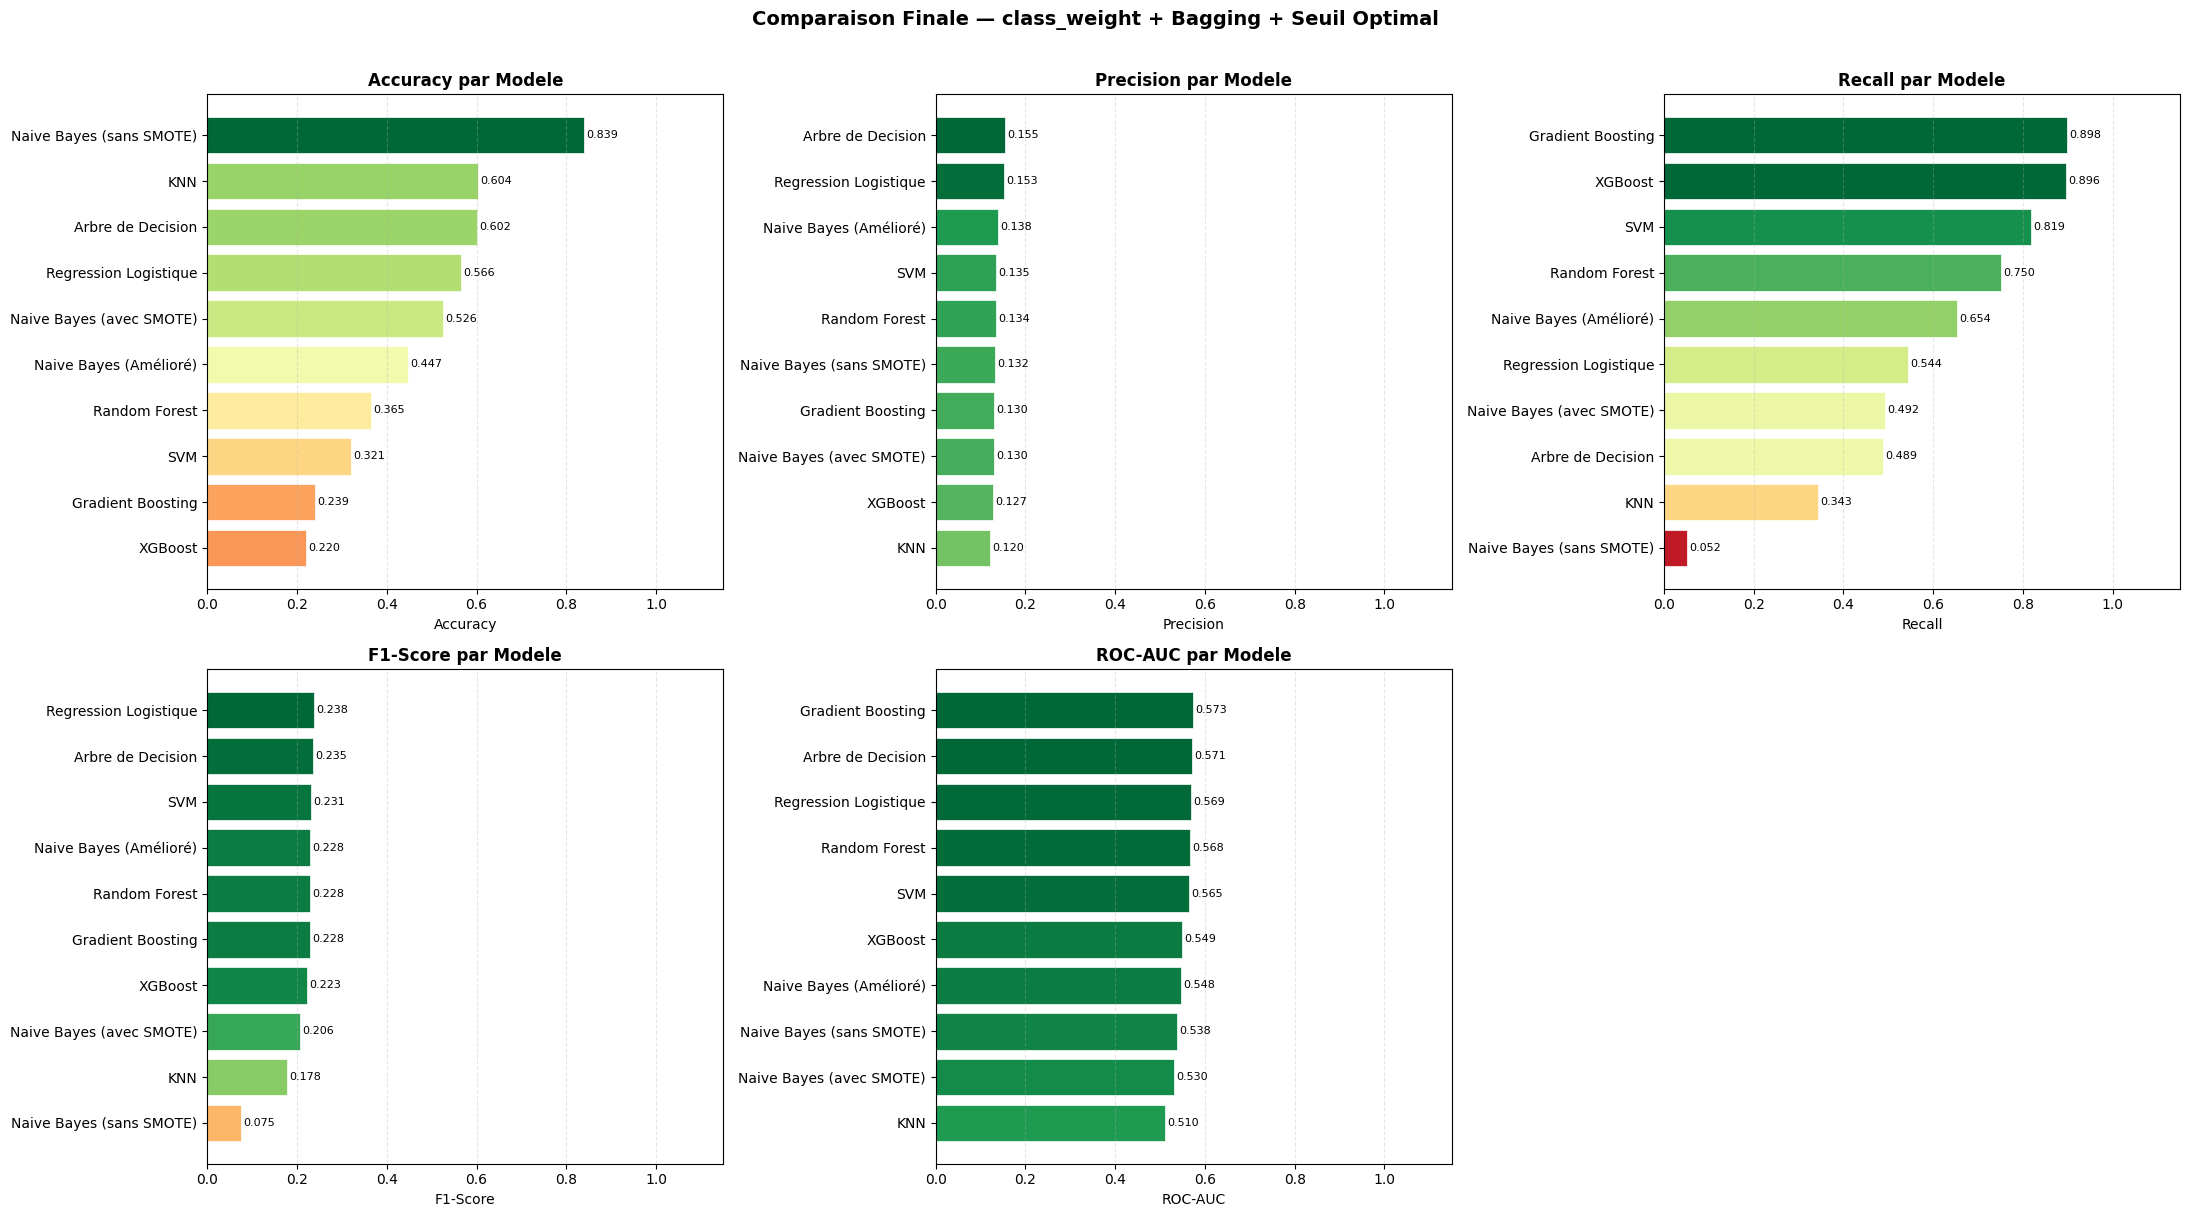

In [ ]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
fig, axes = plt.subplots(2, 3, figsize=(22, 12))
axes = axes.ravel()

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]
    data = results_df.sort_values(metric, ascending=True)
    colors = plt.cm.RdYlGn(data[metric] / data[metric].max())
    ax.barh(data['Modele'], data[metric], color=colors, edgecolor='white', linewidth=0.5)
    ax.set_xlabel(metric, fontsize=10)
    ax.set_xlim([0, 1.15])
    ax.set_title(f'{metric} par Modele', fontweight='bold', fontsize=12)
    ax.grid(axis='x', alpha=0.3, linestyle='--')
    for j, (_, row) in enumerate(data.iterrows()):
        ax.text(row[metric] + 0.005, j, f'{row[metric]:.3f}', va='center', fontsize=8)

axes[-1].remove()
plt.suptitle('Comparaison Finale — class_weight + Bagging + Seuil Optimal',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()


### Courbes ROC Comparatives

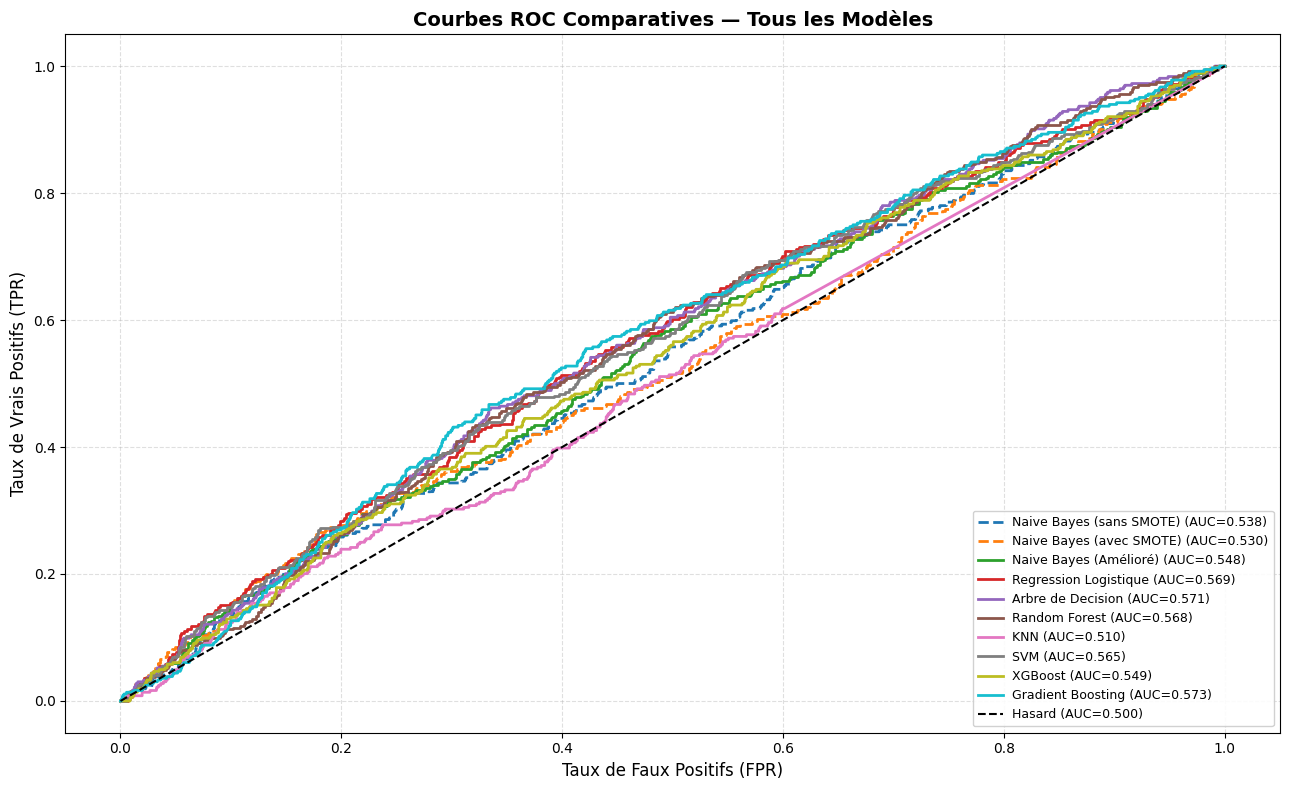

In [ ]:
plt.figure(figsize=(13, 8))
couleurs = plt.cm.tab10(np.linspace(0, 1, len(all_models)))

for (name, (y_p, y_pr)), color in zip(all_models.items(), couleurs):
    fpr_m, tpr_m, _ = roc_curve(y_test, y_pr)
    auc_m = auc(fpr_m, tpr_m)

    ls = '--' if 'sans SMOTE' in name or 'avec SMOTE' in name else '-'
    plt.plot(fpr_m, tpr_m, label=f'{name} (AUC={auc_m:.3f})',
             linewidth=2, color=color, linestyle=ls)

plt.plot([0,1],[0,1],'k--', label='Hasard (AUC=0.500)', linewidth=1.5)
plt.xlabel('Taux de Faux Positifs (FPR)', fontsize=12)
plt.ylabel('Taux de Vrais Positifs (TPR)', fontsize=12)
plt.title('Courbes ROC Comparatives — Tous les Modèles', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=9, framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout(); plt.show()


### Matrices de Confusion — Top 3 Modèles

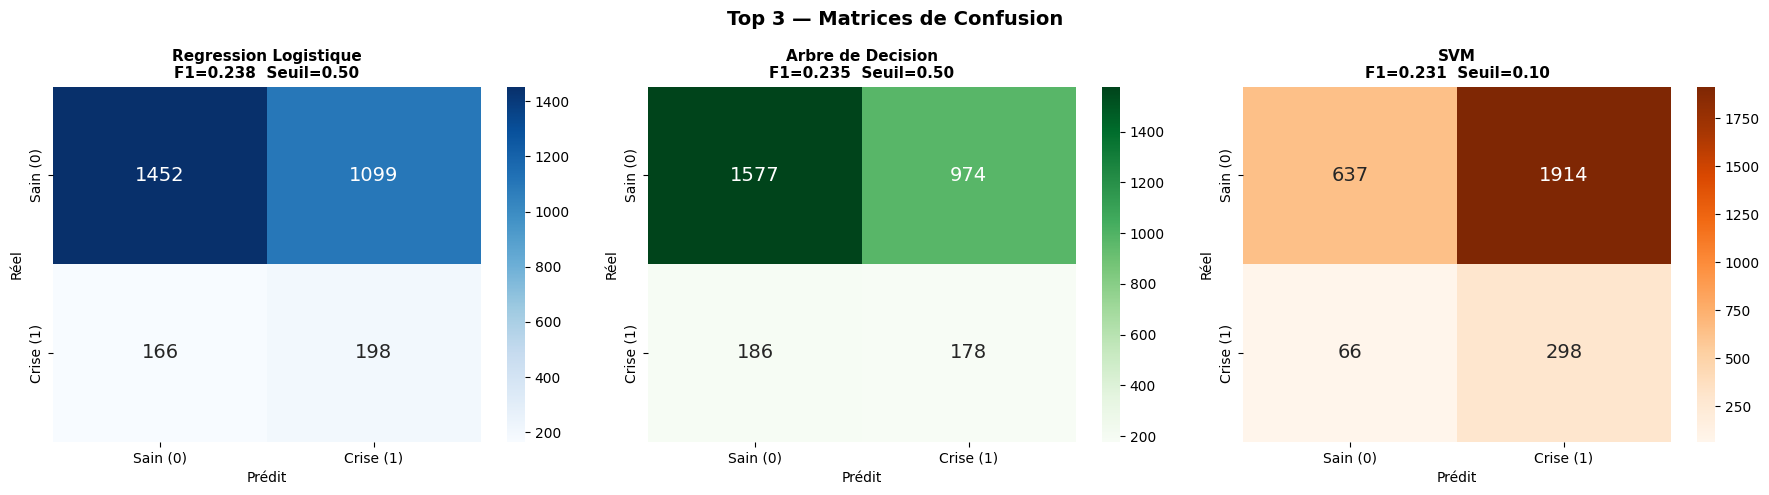

In [ ]:
top3 = results_df.head(3)['Modele'].tolist()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cmaps = ['Blues', 'Greens', 'Oranges']
noms_classes_str = ['Sain (0)', 'Crise (1)']

for i, (name, cmap) in enumerate(zip(top3, cmaps)):
    y_p, _ = all_models[name]
    cm = confusion_matrix(y_test, y_p)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, ax=axes[i],
                xticklabels=noms_classes_str, yticklabels=noms_classes_str,
                annot_kws={'size': 14})
    axes[i].set_title(
        f'{name}\nF1={f1_score(y_test,y_p):.3f}  Seuil={seuils_utilises[name]:.2f}',
        fontweight='bold', fontsize=11)
    axes[i].set_ylabel('Réel'); axes[i].set_xlabel('Prédit')

plt.suptitle('Top 3 — Matrices de Confusion', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


### Analyse des Erreurs — Meilleur Modèle

In [ ]:
print('='*70)
print('   ANALYSE DES ERREURS — MEILLEUR MODELE')
print('='*70)

best_name = results_df.iloc[0]['Modele']
best_preds = np.array(all_models[best_name][0])
y_test_arr = np.array(y_test)

VP = ((best_preds == 1) & (y_test_arr == 1)).sum()
VN = ((best_preds == 0) & (y_test_arr == 0)).sum()
FP = ((best_preds == 1) & (y_test_arr == 0)).sum()
FN = ((best_preds == 0) & (y_test_arr == 1)).sum()
total = len(y_test_arr)

print(f'\nMeilleur modèle : {best_name}')
print(f'  F1-Score : {results_df.iloc[0]["F1-Score"]:.3f}')
print(f'  Seuil    : {results_df.iloc[0]["Seuil"]:.2f}')
print(f'\nBILAN CLINIQUE ({total} patients) :')
print(f'  Vrais Positifs  (crises détectées)     : {VP} ({VP/total*100:.1f}%)')
print(f'  Vrais Négatifs  (sains identifiés)     : {VN} ({VN/total*100:.1f}%)')
print(f'  Faux Positifs   (fausses alertes)      : {FP} ({FP/total*100:.1f}%)')
print(f'  Faux Négatifs   (crises manquées !)    : {FN} ({FN/total*100:.1f}%)')
print('\n  Les Faux Négatifs sont les plus dangereux en médecine !')
print('   Des patients à risque ne seraient PAS pris en charge.')


   ANALYSE DES ERREURS — MEILLEUR MODELE

Meilleur modèle : Regression Logistique
  F1-Score : 0.238
  Seuil    : 0.50

BILAN CLINIQUE (2915 patients) :
  Vrais Positifs  (crises détectées)     : 198 (6.8%)
  Vrais Négatifs  (sains identifiés)     : 1452 (49.8%)
  Faux Positifs   (fausses alertes)      : 1099 (37.7%)
  Faux Négatifs   (crises manquées !)    : 166 (5.7%)

  Les Faux Négatifs sont les plus dangereux en médecine !
   Des patients à risque ne seraient PAS pris en charge.


## 8. Résumé Final et Recommandations Cliniques

In [ ]:
print('='*80)
print('   RESUME FINAL ET RECOMMANDATIONS CLINIQUES')
print('='*80)

best   = results_df.iloc[0]
second = results_df.iloc[1]

print(f'\n=== MEILLEUR MODELE : {best["Modele"]} ===')
print(f'   Seuil décision : {best["Seuil"]:.2f}')
print(f'   Accuracy       : {best["Accuracy"]:.3f}')
print(f'   Precision      : {best["Precision"]:.3f}')
print(f'   Recall         : {best["Recall"]:.3f}')
print(f'   F1-Score       : {best["F1-Score"]:.3f}  ← critère principal')
print(f'   ROC-AUC        : {best["ROC-AUC"]:.3f}')
print(f'\n2ème place : {second["Modele"]} (F1={second["F1-Score"]:.3f})')

print('''
METHODOLOGIE RETENUE :
  1. class_weight='balanced' (ou priors/scale_pos_weight selon le modèle)
     => Equivalent de class_weight pour chaque algorithme
  2. BaggingClassifier pour les modèles sans class_weight natif
  3. Split 60/20/20 stratifié : validation séparée pour le seuil
  4. Seuil optimal sur jeu de validation (0.10 à 0.90 par pas de 0.05)

RECOMMANDATIONS CLINIQUES :
  1. Utiliser le seuil optimal trouvé (pas 0.5 par défaut)
  2. Privilegier le Recall : rater une crise est plus grave qu'une fausse alerte
  3. Valider sur un jeu externe avant tout déploiement
  4. Surveiller la dérive du modèle dans le temps
''')


   RESUME FINAL ET RECOMMANDATIONS CLINIQUES

=== MEILLEUR MODELE : Regression Logistique ===
   Seuil décision : 0.50
   Accuracy       : 0.566
   Precision      : 0.153
   Recall         : 0.544
   F1-Score       : 0.238  ← critère principal
   ROC-AUC        : 0.569

2ème place : Arbre de Decision (F1=0.235)

METHODOLOGIE RETENUE :
  1. class_weight='balanced' (ou priors/scale_pos_weight selon le modèle)
     => Equivalent de class_weight pour chaque algorithme
  2. BaggingClassifier pour les modèles sans class_weight natif
  3. Split 60/20/20 stratifié : validation séparée pour le seuil
  4. Seuil optimal sur jeu de validation (0.10 à 0.90 par pas de 0.05)

RECOMMANDATIONS CLINIQUES :
  1. Utiliser le seuil optimal trouvé (pas 0.5 par défaut)
  2. Privilegier le Recall : rater une crise est plus grave qu'une fausse alerte
  3. Valider sur un jeu externe avant tout déploiement
  4. Surveiller la dérive du modèle dans le temps



## Export CSV — Prédictions Finales (Meilleur Modèle)

In [ ]:
best_model_name = results_df.iloc[0]['Modele']

pipeline_map = {
    'Naive Bayes (sans SMOTE)': nb_pipeline,
    'Naive Bayes (avec SMOTE)': smote_pipeline,
    'Naive Bayes (Amélioré)':   best_nb_model,
    'Regression Logistique':    best_lr,
    'Arbre de Decision':        best_dt,
    'Random Forest':            best_rf,
    'KNN':                      best_knn,
    'SVM':                      best_svm,
    'XGBoost':                  best_xgb,
    'Gradient Boosting':        best_gb,
}
seuil_map = {
    'Naive Bayes (sans SMOTE)': 0.50,
    'Naive Bayes (avec SMOTE)': 0.50,
    'Naive Bayes (Amélioré)':   seuil_nb_opt,
    'Regression Logistique':    seuil_lr,
    'Arbre de Decision':        seuil_dt,
    'Random Forest':            seuil_rf,
    'KNN':                      seuil_knn,
    'SVM':                      seuil_svm,
    'XGBoost':                  seuil_xgb,
    'Gradient Boosting':        seuil_gb,
}

best_pipeline_obj = pipeline_map[best_model_name]
best_seuil_final  = seuil_map[best_model_name]

proba_finales       = best_pipeline_obj.predict_proba(features)[:, 1]
predictions_finales = (proba_finales >= best_seuil_final).astype(int)

df_resultats = pl.DataFrame({
    'patid':      df['patid'],
    'prediction': predictions_finales
})

nom_fichier = 'predictions_exacerbations_final.csv'
df_resultats.write_csv(nom_fichier)

print(f'Fichier "{nom_fichier}" généré !')
print(f'  Modèle    : {best_model_name}')
print(f'  Seuil     : {best_seuil_final:.2f}')
print(f'  Nb preds  : {len(predictions_finales)}')
print(f'  % crises  : {predictions_finales.mean():.1%}')
print(df_resultats.head(10))


Fichier "predictions_exacerbations_final.csv" généré !
  Modèle    : Regression Logistique
  Seuil     : 0.50
  Nb preds  : 14575
  % crises  : 44.0%
shape: (10, 2)
┌────────────┬────────────┐
│ patid      ┆ prediction │
│ ---        ┆ ---        │
│ i64        ┆ i64        │
╞════════════╪════════════╡
│ 1073754155 ┆ 1          │
│ 1073799394 ┆ 1          │
│ 1073854918 ┆ 1          │
│ 1073898249 ┆ 1          │
│ 1073913003 ┆ 0          │
│ 1073928980 ┆ 1          │
│ 1074030062 ┆ 1          │
│ 1074078078 ┆ 1          │
│ 1074166886 ┆ 1          │
│ 1074184402 ┆ 0          │
└────────────┴────────────┘
